# UTS Graf Sains Data

Nama / NIM: (Tarisa Dwita Abadi/23031554134)

Dataset: RetailRocket (events.csv), database Neo4j `retail`

Periode: P1 (training) 2015-05-28 sampai 2015-06-28, P2 (testing) 2015-07-23 sampai 2015-08-23

# 1. Tugas Pendahuluan
## 1.1 Persiapan dan Perkenalan Lingkungan

Langkah 1, buat environment baru (di terminal):

```powershell
python -m venv myvenv
# atau pakai uv
uv venv myvenv --python 3.10
```

Langkah 2, matikan environment lain lalu aktifkan `myvenv`:

```powershell
conda deactivate
.\myvenv\Scripts\Activate.ps1
```

Langkah 3, install paket dari `requirements.txt`:

```powershell
uv pip install -r requirements.txt
```

In [38]:
import sys, platform
print("Python      :", sys.version.split()[0])
print("Interpreter :", sys.executable)
print("Venv aktif  :", sys.prefix != sys.base_prefix)
print("OS          :", platform.platform())

Python      : 3.12.7
Interpreter : d:\uts-graf\myvenv\Scripts\python.exe
Venv aktif  : True
OS          : Windows-11-10.0.26200-SP0


Catatan: isi `requirements.txt` di soal bentrok (`neo4j>=4.0,<4.3` dan `neo4j==4.2.1`), padahal `execute_query` baru ada di driver 5.x. Jadi dipakai `neo4j>=5.8,<6`.

In [39]:
%%writefile requirements.txt
neo4j>=5.8,<6
pandas
numpy
scipy
scikit-learn
networkx
matplotlib
tqdm
jupyter

Overwriting requirements.txt


In [ ]:
from importlib.metadata import version, PackageNotFoundError
for pkg in ["neo4j", "pandas", "numpy", "scipy", "scikit-learn", "networkx", "matplotlib", "tqdm"]:
    try:
        print(f"{pkg:<14}{version(pkg)}")
    except PackageNotFoundError:
        print(f"{pkg:<14}BELUM TERPASANG")

neo4j         6.4.1
pandas        3.0.6
numpy         2.5.4
scipy         1.18.1
scikit-learn  1.9.1
networkx      3.7
matplotlib    3.11.2
tqdm          4.70.1


Uraian: notebook jalan di dalam `myvenv`, jadi paketnya terpisah dari proyek lain.

## 1.2 Mempelajari Penggunaan Driver Neo4j

Langkah 2, string koneksi. Dipakai `bolt://127.0.0.1:7687` dan database `retail` (bukan `neo4j`) supaya datanya terpisah.

In [ ]:
from neo4j import GraphDatabase, RoutingControl, Result

URI  = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "password")     
DB   = "retail"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke", URI)

try:
    with driver.session(database="system") as s:
        s.run(f"CREATE DATABASE {DB} IF NOT EXISTS WAIT").consume()
    print(f"Database '{DB}' siap dipakai")
except Exception as e:
    print("Tidak bisa membuat database (mungkin Community Edition):", e)

Terhubung ke bolt://127.0.0.1:7687
Database 'retail' siap dipakai


Langkah 3, buat node dan relasi dengan `execute_query`.

In [42]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DB,
    )

Langkah 4, cetak hasilnya.

In [43]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DB, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

# driver ditutup oleh with, jadi dibuat lagi
driver = GraphDatabase.driver(URI, auth=AUTH)

Guinevere
Lancelot
Merlin


Fungsi bantu untuk menggambar graf. `fetch_graph()` mengambil node dan relasi dari Neo4j, lalu `draw_graph()` menggambarnya dengan networkx. Relasi yang sama dan berulang (misal VIEWED 5 kali) digambar jadi satu garis berlabel ×n.

In [44]:
import math
from collections import defaultdict
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

plt.rcParams["figure.dpi"] = 110
NODE_COLOR = {"Person": "#C990C0", "Visitor": "#F79767", "Item": "#57C7E3", "Rekomendasi": "#8DCC93"}
EDGE_COLOR = {"KNOWS": "#6A1B9A", "VIEWED": "#9AA0A6", "ADDED_TO_CART": "#F9A825",
              "BOUGHT": "#2E7D32", "SIMILAR_TO": "#D81B60"}

def idn(x):
    # format angka: 1234567 jadi 1.234.567
    return f"{int(x):,}".replace(",", ".")

def run_df(query, **params):
    # jalankan cypher, hasilnya jadi dataframe
    records, _, keys = driver.execute_query(query, database_=DB, **params)
    return pd.DataFrame([r.data() for r in records], columns=keys)

def fetch_graph(query, **params):
    # ambil node dan relasi dari neo4j, jadikan graph networkx
    g = driver.execute_query(query, database_=DB, result_transformer_=Result.graph, **params)
    G = nx.MultiDiGraph()
    for n in g.nodes:
        G.add_node(n.element_id, label=(sorted(n.labels)[0] if n.labels else "?"), props=dict(n.items()))
    for r in g.relationships:
        G.add_edge(r.start_node.element_id, r.end_node.element_id, key=r.element_id,
                   type=r.type, props=dict(r.items()))
    return G

def node_name(d):
    p, lab = d["props"], d["label"]
    if "name" in p:
        return str(p["name"])
    if lab == "Visitor":
        return f"V{p.get('visitorId')}"
    if lab in ("Item", "Rekomendasi"):
        return f"I{p.get('itemId')}"
    return lab

def layout(G, seed=42):
    H = nx.Graph(G)
    n = max(H.number_of_nodes(), 1)
    return nx.spring_layout(H, seed=seed, k=1.5 / math.sqrt(n), iterations=200)

def draw_graph(G, ax=None, pos=None, title="", seed=42, label_edges="auto", highlight=None):
    own = ax is None
    if own:
        _, ax = plt.subplots(figsize=(10, 7))
    if pos is None:
        pos = layout(G, seed)

    groups = defaultdict(lambda: defaultdict(list))
    for u, v, d in G.edges(data=True):
        if u in pos and v in pos:
            groups[(u, v)][d["type"]].append(d["props"])
    n_lines = sum(len(t) for t in groups.values())
    show_lbl = (n_lines <= 30) if label_edges == "auto" else bool(label_edges)

    for (u, v), types in groups.items():
        k, has_rev = len(types), (v, u) in groups
        for idx, (typ, plist) in enumerate(sorted(types.items())):
            rad = 0.22 * (idx - (k - 1) / 2) if k > 1 else (0.18 if has_rev else 0.0)
            col = EDGE_COLOR.get(typ, "#888888")
            ax.annotate("", xy=pos[v], xytext=pos[u], zorder=1,
                        arrowprops=dict(arrowstyle="-|>", color=col, lw=2.4 if typ == "SIMILAR_TO" else 1.2,
                                        alpha=0.9, shrinkA=8, shrinkB=8, mutation_scale=11,
                                        connectionstyle=f"arc3,rad={rad}"))
            if typ == "SIMILAR_TO" or show_lbl:
                (x1, y1), (x2, y2) = pos[u], pos[v]
                mx, my = (x1 + x2) / 2 + 0.5 * rad * (y2 - y1), (y1 + y2) / 2 - 0.5 * rad * (x2 - x1)
                if typ == "SIMILAR_TO":
                    txt = f"{plist[0].get('score', 0):.3f}"
                else:
                    txt = typ if len(plist) == 1 else f"{typ} ×{len(plist)}"
                ax.text(mx, my, txt, fontsize=6.5, color=col, ha="center", va="center", zorder=2,
                        bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.75))

    n_nodes = G.number_of_nodes()
    size = 700 if n_nodes <= 25 else (260 if n_nodes <= 80 else 70)
    labels = sorted({d["label"] for _, d in G.nodes(data=True)})
    for lab in labels:
        nodes = [n for n, d in G.nodes(data=True) if d["label"] == lab and n in pos]
        if not nodes:
            continue
        xy = np.array([pos[n] for n in nodes])
        hl = [bool(highlight and highlight(G.nodes[n])) for n in nodes]
        ax.scatter(xy[:, 0], xy[:, 1], s=size, c=NODE_COLOR.get(lab, "#BDBDBD"), zorder=3,
                   edgecolors=["black" if h else "white" for h in hl],
                   linewidths=[2.5 if h else 1.2 for h in hl])
        if n_nodes <= 40:
            for n in nodes:
                ax.annotate(node_name(G.nodes[n]), pos[n], xytext=(0, -(math.sqrt(size) / 2 + 4)),
                            textcoords="offset points", ha="center", va="top", fontsize=7, zorder=4)

    handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=NODE_COLOR.get(l, "#BDBDBD"),
                      markersize=9, label=l) for l in labels]
    etypes = sorted({d["type"] for *_, d in G.edges(data=True)})
    handles += [Line2D([0], [0], color=EDGE_COLOR.get(t, "#888888"), lw=2, label=t) for t in etypes]
    ax.legend(handles=handles, loc="upper right", fontsize=7, frameon=True)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    ax.margins(0.15)
    if own:
        plt.tight_layout()
        plt.show()
    return pos

def draw_projection(W, names, title, color, ax=None):
    # gambar graf proyeksi dari matriks similarity
    G = nx.Graph()
    G.add_nodes_from(range(len(names)))
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            if W[i, j] > 0:
                G.add_edge(i, j, w=float(W[i, j]))
    pos = nx.circular_layout(G)
    own = ax is None
    if own:
        _, ax = plt.subplots(figsize=(6, 6))
    nx.draw_networkx_edges(G, pos, width=[1 + 5 * G[u][v]["w"] for u, v in G.edges],
                           edge_color="#999999", alpha=.8, ax=ax)
    nx.draw_networkx_nodes(G, pos, node_color=color, node_size=1100, edgecolors="white", ax=ax)
    nx.draw_networkx_labels(G, pos, labels={i: names[i] for i in G}, font_size=6, ax=ax)
    nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"{G[u][v]['w']:.2f}" for u, v in G.edges},
                                 font_size=7, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
    if own:
        plt.tight_layout()
        plt.show()

### Pertanyaan Pendahuluan
#### Soal 1. Nama database yang dipakai

In [45]:
print('Database pada tutorial soal  : "neo4j" (database default, database_="neo4j")')
print("Database yang dipakai di sini:", DB)

Database pada tutorial soal  : "neo4j" (database default, database_="neo4j")
Database yang dipakai di sini: retail


Jawab: `neo4j` (database default). Di sini diganti `retail`.

#### Soal 2. Akses lain ke database lain dalam 1 instance

In [46]:
with driver.session(database="system") as s:
    dbs = [(r["name"], r["currentStatus"]) for r in s.run("SHOW DATABASES")]
print(pd.DataFrame(dbs, columns=["database", "status"]).drop_duplicates().to_string(index=False), "\n")

for name, status in dbs:
    if name != "system" and status == "online":
        n = driver.execute_query("MATCH (n) RETURN count(n) AS c", database_=name).records[0]["c"]
        print(f"database_='{name}' -> jumlah simpul: {n}")

 database status
    movie online
movielens online
    neo4j online
   retail online
   system online 

database_='movie' -> jumlah simpul: 0
database_='movielens' -> jumlah simpul: 10372
database_='neo4j' -> jumlah simpul: 0
database_='retail' -> jumlah simpul: 439788


Jawab:
- Python: `database_="nama_db"` pada `execute_query`, atau `driver.session(database="nama_db")`
- Neo4j Browser: `:use retail`
- Cypher: `USE retail MATCH (n) RETURN count(n)`
- DDL (dijalankan di database `system`): `SHOW DATABASES`, `CREATE DATABASE`, `ALTER DATABASE`, `DROP DATABASE`
- DML (`MATCH`, `MERGE`, `CREATE`, `SET`, `DELETE`) jalan di database yang dipilih

Hasil di atas menampilkan daftar database di instance ini dan jumlah simpul masing-masing.

#### Soal 3. Jenis graf pertemanan

Simpul: 4 | Relasi: 3
Out-degree : {'Arthur': 3, 'Guinevere': 0, 'Lancelot': 0, 'Merlin': 0}
In-degree  : {'Arthur': 0, 'Guinevere': 1, 'Lancelot': 1, 'Merlin': 1}
Teman Guinevere (searah  ->): []
Teman Guinevere (tanpa arah -): ['Arthur']

Cypher (salin ke Neo4j Browser):
MATCH p = (a:Person)-[:KNOWS]->(b:Person) RETURN p


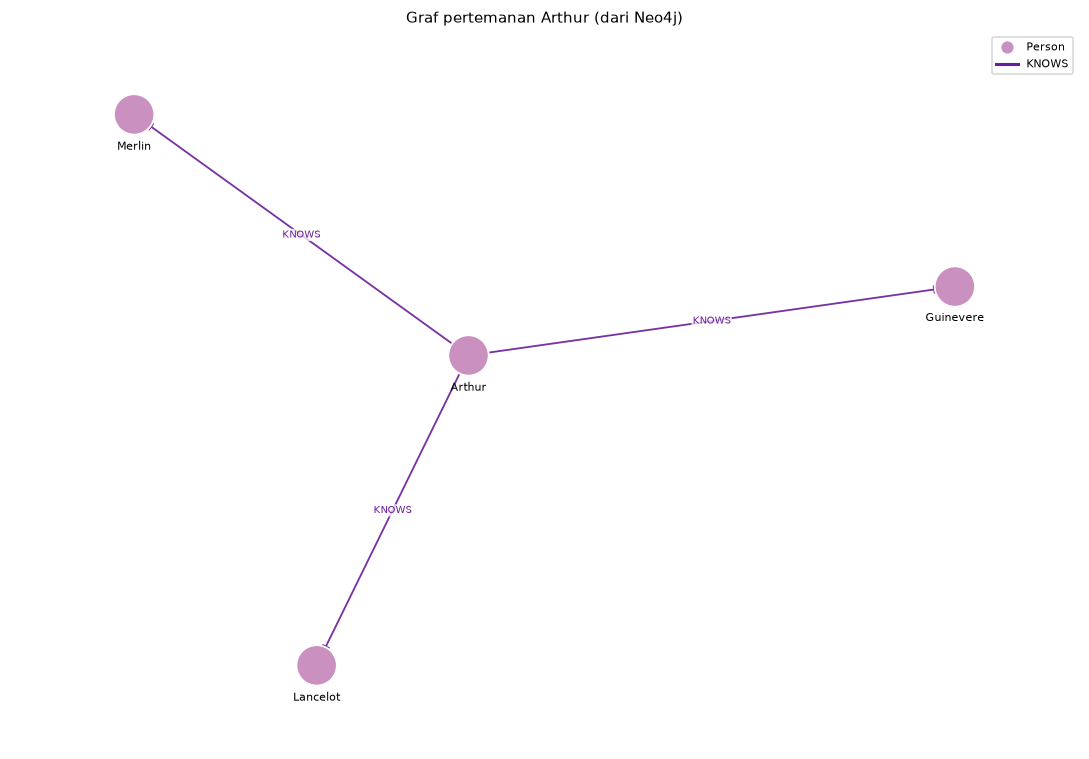

{'4:6829035e-1eb5-43c9-b183-11299c1f6774:439784': array([-7.33804658e-05, -1.58954053e-05]),
 '4:6829035e-1eb5-43c9-b183-11299c1f6774:439785': array([1.       , 0.2166163]),
 '4:6829035e-1eb5-43c9-b183-11299c1f6774:439786': array([-0.3123265 , -0.97451758]),
 '4:6829035e-1eb5-43c9-b183-11299c1f6774:439787': array([-0.68760012,  0.75791717])}

In [47]:
G_friend = fetch_graph("MATCH p = (a:Person)-[:KNOWS]->(b:Person) RETURN p")
print("Simpul:", G_friend.number_of_nodes(), "| Relasi:", G_friend.number_of_edges())
print("Out-degree :", {node_name(G_friend.nodes[n]): d for n, d in G_friend.out_degree()})
print("In-degree  :", {node_name(G_friend.nodes[n]): d for n, d in G_friend.in_degree()})

for ket, pola in [("searah  ->", "(a:Person {name:$n})-[:KNOWS]->(f)"), ("tanpa arah -", "(a:Person {name:$n})-[:KNOWS]-(f)")]:
    rec, _, _ = driver.execute_query(f"MATCH {pola} RETURN f.name AS f", n="Guinevere", database_=DB)
    print(f"Teman Guinevere ({ket}):", [r["f"] for r in rec])

Q = "MATCH p = (a:Person)-[:KNOWS]->(b:Person) RETURN p"
print("\nCypher (salin ke Neo4j Browser):\n" + Q)
draw_graph(G_friend, title="Graf pertemanan Arthur (dari Neo4j)")

Jawab: graf berarah (Arthur ke teman-temannya), tidak berbobot, dan bentuknya bintang. Arthur punya 3 teman (out-degree 3), tiap teman in-degree 1. Hanya ada 1 label (`Person`) dan 1 tipe relasi (`KNOWS`).

Karena searah, Guinevere tidak punya teman keluar, tapi kalau arahnya diabaikan dia berteman dengan Arthur (lihat hasil di atas).

### CYPHER Total Reset

In [48]:
# MATCH (n) DETACH DELETE n; dihapus per 10.000 simpul
with driver.session(database=DB) as s:
    while s.run("MATCH (n) WITH n LIMIT 10000 DETACH DELETE n RETURN count(*) AS c").single()["c"]:
        pass
print("Jumlah simpul setelah reset:", driver.execute_query("MATCH (n) RETURN count(n) AS c", database_=DB).records[0]["c"])

Jumlah simpul setelah reset: 0


## 1.3 Impor Data RetailRocket ke Neo4j
Sumber data: Roman Zykov.

Langkah 1, unduh data dari Kaggle:

```powershell
# Windows PowerShell
curl.exe -L -o ecommerce-dataset.zip `
  https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset
```
```bash
# Linux / macOS
curl -L -o ecommerce-dataset.zip \
  https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset
```
Sel di bawah menjalankan hal yang sama lewat Python, dan dilewati kalau `events.csv` sudah ada.

In [49]:
import os, shutil, subprocess, zipfile

DATA_DIR = "data"
URL = "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"
os.makedirs(DATA_DIR, exist_ok=True)

if os.path.exists(os.path.join(DATA_DIR, "events.csv")):
    print("events.csv sudah ada -> unduhan dilewati")
else:
    curl = shutil.which("curl.exe") or shutil.which("curl")
    subprocess.run([curl, "-L", "-o", "ecommerce-dataset.zip", URL], check=True)
    with zipfile.ZipFile("ecommerce-dataset.zip") as z:
        z.extract("events.csv", DATA_DIR)
    print("events.csv berhasil diunduh")

events.csv sudah ada -> unduhan dilewati


Langkah 2, fitur data:

| Fitur | Arti |
|---|---|
| `timestamp` | waktu dalam unix epoch (milidetik) |
| `visitorid` | ID unik pengunjung |
| `event` | jenis interaksi: `view`, `addtocart`, `transaction` |
| `itemid` | ID unik produk |
| `transactionid` | ID transaksi, hanya terisi saat event `transaction` |

In [50]:
df = pd.read_csv(os.path.join(DATA_DIR, "events.csv"))
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")     # ubah epoch (ms) ke datetime

print("Shape:", df.shape)
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "null": df.isna().sum(), "unik": df.nunique()}))
print(df["event"].value_counts(), "\n")
print("Rentang waktu :", df["datetime"].min(), "->", df["datetime"].max())
print("transactionid terisi  <=>  event == 'transaction' :", bool((df["transactionid"].notna() == (df["event"] == "transaction")).all()))

Shape: (2756101, 6)


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


,dtype,null,unik
timestamp,int64,0,2750455
visitorid,int64,0,1407580
event,str,0,3
itemid,int64,0,235061
transactionid,float64,2733644,17672
datetime,datetime64[ms],0,2750455


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64 

Rentang waktu : 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
transactionid terisi  <=>  event == 'transaction' : True


Uraian: data punya 2.756.101 baris. Event `view` 2.664.312, `addtocart` 69.332, `transaction` 22.457, jadi hampir semuanya view. `transactionid` kosong kecuali pada event transaction. Rentang waktu 2015-05-03 sampai 2015-09-18.

Langkah 3, buat session Neo4j baru:

In [51]:
driver.close()
driver = GraphDatabase.driver(URI, auth=AUTH)
session = driver.session(database="system")           # session ke database system
print([r["name"] for r in session.run("SHOW DATABASES")])
session.close()

['movie', 'movielens', 'neo4j', 'retail', 'system']


Versi pakai argparse (di Jupyter argumennya dikosongkan dengan `parse_arguments([])`):

In [52]:
import argparse

def parse_arguments(argv=None):
    parser = argparse.ArgumentParser(description="Impor dataset RetailRocket (events.csv) ke database Neo4J.")
    parser.add_argument("-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default=os.environ.get("NEO4J_PASSWORD", AUTH[1]), help="Password Neo4J")
    parser.add_argument("-b", "--bolt", default=URI, help=f"Neo4J URI / Bolt (default: {URI})")
    parser.add_argument("-s", "--source", default="data", help="Direktori/folder sumber data (default: data)")
    parser.add_argument("-d", "--database", default=DB, help=f"Nama database (default: {DB})")
    return parser.parse_args(argv)

args = parse_arguments([])
print({k: (v if k != "password" else "***") for k, v in vars(args).items()})

{'user': 'neo4j', 'password': '***', 'bolt': 'bolt://127.0.0.1:7687', 'source': 'data', 'database': 'retail'}


Cek file `events.csv` dan koneksi ke database:

In [53]:
csv_file_path = os.path.join(args.source, "events.csv")
if not os.path.exists(csv_file_path):
    raise FileNotFoundError(f"File '{csv_file_path}' tidak ditemukan!")

try:
    driver.close()
    driver = GraphDatabase.driver(args.bolt, auth=(args.user, args.password))
    driver.verify_connectivity()
    DB = args.database
    print(f"Terhubung ke {args.bolt} | database = {DB} | sumber = {csv_file_path}")
except Exception as e:
    raise RuntimeError(f"Gagal terhubung ke database: {e}")

Terhubung ke bolt://127.0.0.1:7687 | database = retail | sumber = data\events.csv


Langkah 4, import per batch. Data dibaca per chunk lalu dikirim ke Neo4j per batch pakai `UNWIND`. `transactionid` yang kosong diubah jadi string kosong.

In [54]:
from tqdm import tqdm

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE").consume()
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE").consume()

def count_rows(path):
    with open(path, "rb") as f:
        return sum(1 for _ in f) - 1                      # kurangi baris header

def run_import(csv_file_path, batch_size=20000):
    with driver.session(database=DB) as session:
        create_constraints(session)

        print(f"Membaca file data dari: {csv_file_path}")
        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

        total_rows = count_rows(csv_file_path)
        total_chunks = (total_rows // batch_size) + 1

        print("Memulai proses impor data ke Neo4j...")
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
            # Membersihkan data null/NaN pada transactionid
            chunk["transactionid"] = chunk["transactionid"].apply(lambda x: "" if pd.isna(x) else str(int(x)))
            records = chunk.to_dict(orient="records")
            session.execute_write(import_batch, records)
    print("Proses impor berhasil.")

Langkah 5, Cypher untuk import. Tiap baris jadi node `Visitor`, node `Item`, dan 1 relasi sesuai event (view jadi VIEWED, addtocart jadi ADDED_TO_CART, transaction jadi BOUGHT).

In [55]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

Uji coba import dengan 1.000 baris pertama, lalu database dikosongkan lagi. Import yang sebenarnya ada di 2.1 soal 2.

In [56]:
sample_path = os.path.join(args.source, "events_sample.csv")
pd.read_csv(csv_file_path, nrows=1000).to_csv(sample_path, index=False)

driver.execute_query("MATCH (n) DETACH DELETE n", database_=DB)
run_import(sample_path, batch_size=250)
print("Simpul :", driver.execute_query("MATCH (n) RETURN count(n) AS c", database_=DB).records[0]["c"])
print("Relasi :", driver.execute_query("MATCH ()-[r]->() RETURN count(r) AS c", database_=DB).records[0]["c"], "(harus 1000)")

driver.execute_query("MATCH (n) DETACH DELETE n", database_=DB)
os.remove(sample_path)
print("Database dikosongkan kembali.")

Membaca file data dari: data\events_sample.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:  80%|████████  | 4/5 [00:08<00:02,  2.10s/it]


Proses impor berhasil.
Simpul : 1753
Relasi : 1000 (harus 1000)
Database dikosongkan kembali.


Uraian: relasi yang terbentuk 1.000, sama dengan jumlah baris. Simpul lebih sedikit karena visitor dan item yang sama digabung oleh `MERGE`. Mekanisme import berjalan.

# 2. Soal UTS
## 2.1 Wrangling dan EDA

### Soal 1. Menentukan 2 periode waktu

| Periode | Peran | Rentang |
|---|---|---|
| P1 | training (membentuk graf) | 2015-05-28 sampai sebelum 2015-06-28 |
| P2 | testing (ground truth evaluasi) | 2015-07-23 sampai sebelum 2015-08-23 |

Dua periode ini tidak beririsan.

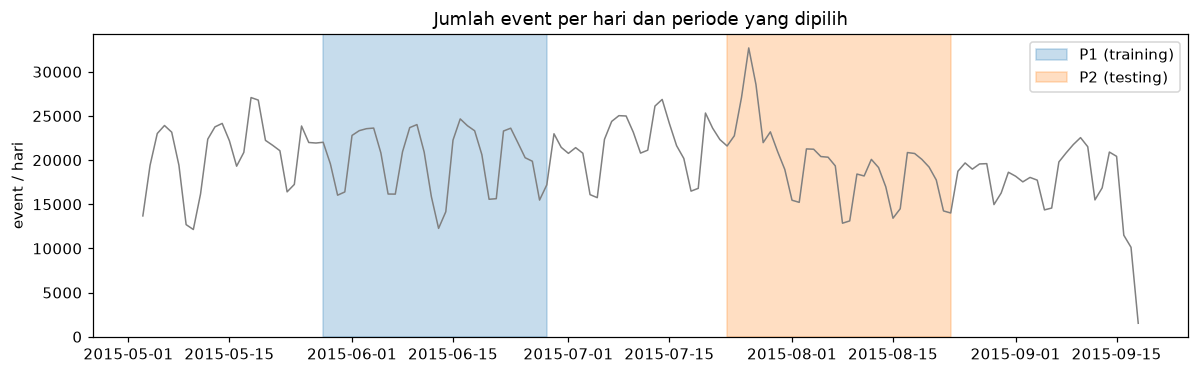

In [57]:
SEED = 42
P1_START, P1_END = "2015-05-28", "2015-06-28"   # training
P2_START, P2_END = "2015-07-23", "2015-08-23"   # testing

daily = df.set_index("datetime").resample("D").size()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily.index, daily.values, color="gray", lw=1)
ax.axvspan(pd.Timestamp(P1_START), pd.Timestamp(P1_END), color="tab:blue", alpha=.25, label="P1 (training)")
ax.axvspan(pd.Timestamp(P2_START), pd.Timestamp(P2_END), color="tab:orange", alpha=.25, label="P2 (testing)")
ax.set_title("Jumlah event per hari dan periode yang dipilih")
ax.set_ylabel("event / hari"); ax.legend()
plt.tight_layout(); plt.show()

### Soal 2. Filter timestamp dan simpan ke csv
`timestamp` dalam milidetik, jadi diubah dulu ke datetime baru difilter.

In [58]:
def filter_period(data, start, end):
    mask = (data["datetime"] >= start) & (data["datetime"] < end)       # batas akhir tidak ikut
    return data.loc[mask]

cols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
p1 = filter_period(df, P1_START, P1_END)
p2 = filter_period(df, P2_START, P2_END)

p1[cols].to_csv(os.path.join(DATA_DIR, "events_p1.csv"), index=False)
p2[cols].to_csv(os.path.join(DATA_DIR, "events_p2.csv"), index=False)

summary = pd.DataFrame({"baris": [len(p1), len(p2)],
                        "visitor unik": [p1.visitorid.nunique(), p2.visitorid.nunique()],
                        "item unik": [p1.itemid.nunique(), p2.itemid.nunique()]}, index=["P1", "P2"])
display(summary)
display(pd.concat({"P1": p1["event"].value_counts(), "P2": p2["event"].value_counts()}, axis=1))

v_both = set(p1.visitorid) & set(p2.visitorid)
i_both = set(p1.itemid) & set(p2.itemid)
print(f"Visitor yang muncul di P1 dan P2: {len(v_both):,}  ({100*len(v_both)/p2.visitorid.nunique():.1f}% dari visitor P2)")
print(f"Item yang muncul di P1 dan P2   : {len(i_both):,}  ({100*len(i_both)/p2.itemid.nunique():.1f}% dari item P2)")

,baris,visitor unik,item unik
P1,622789,321442,118342
P2,610734,337401,118019


,P1,P2
event,,
view,602091,590032
addtocart,15532,15682
transaction,5166,5020


Visitor yang muncul di P1 dan P2: 8,748  (2.6% dari visitor P2)
Item yang muncul di P1 dan P2   : 68,595  (58.1% dari item P2)


Uraian: kedua periode dipilih tidak beririsan dan punya panjang yang sama (satu bulan), sehingga ukuran data P1 dan P2 seimbang dan perbandingannya adil. P1 dipakai membentuk graf, sedangkan P2 hanya dipakai sebagai kunci jawaban evaluasi. Temuan penting dari ringkasan di atas: hanya sebagian kecil visitor P2 yang juga muncul di P1, artinya sebagian besar user P2 tidak punya histori di graf sehingga tidak bisa diberi rekomendasi maupun dievaluasi. Karena itu evaluasi nanti hanya memakai user yang ada di kedua periode.

Lanjutan soal 2: bangun graf di Neo4j dari csv P1. P2 disimpan untuk evaluasi di 2.2.

In [59]:
# kosongkan database dulu
with driver.session(database=DB) as s:
    while s.run("MATCH (n) WITH n LIMIT 10000 DETACH DELETE n RETURN count(*) AS c").single()["c"]:
        pass

run_import(os.path.join(DATA_DIR, "events_p1.csv"), batch_size=20000)

Membaca file data dari: data\events_p1.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 32/32 [03:46<00:00,  7.09s/it]

Proses impor berhasil.


### Soal 3. Komposisi subgraph

,jenis_simpul,jumlah
0,Visitor,321442
1,Item,118342


,jenis_relasi,jumlah
0,VIEWED,602091
1,ADDED_TO_CART,15532
2,BOUGHT,5166


,relasi,jumlah_relasi,visitor_unik,item_unik
0,VIEWED,602091,320813,118184
1,ADDED_TO_CART,15532,8765,8316
2,BOUGHT,5166,2765,3666


Cek terhadap CSV P1 -> visitor unik: 321442 | item unik: 118342 | baris: 622789


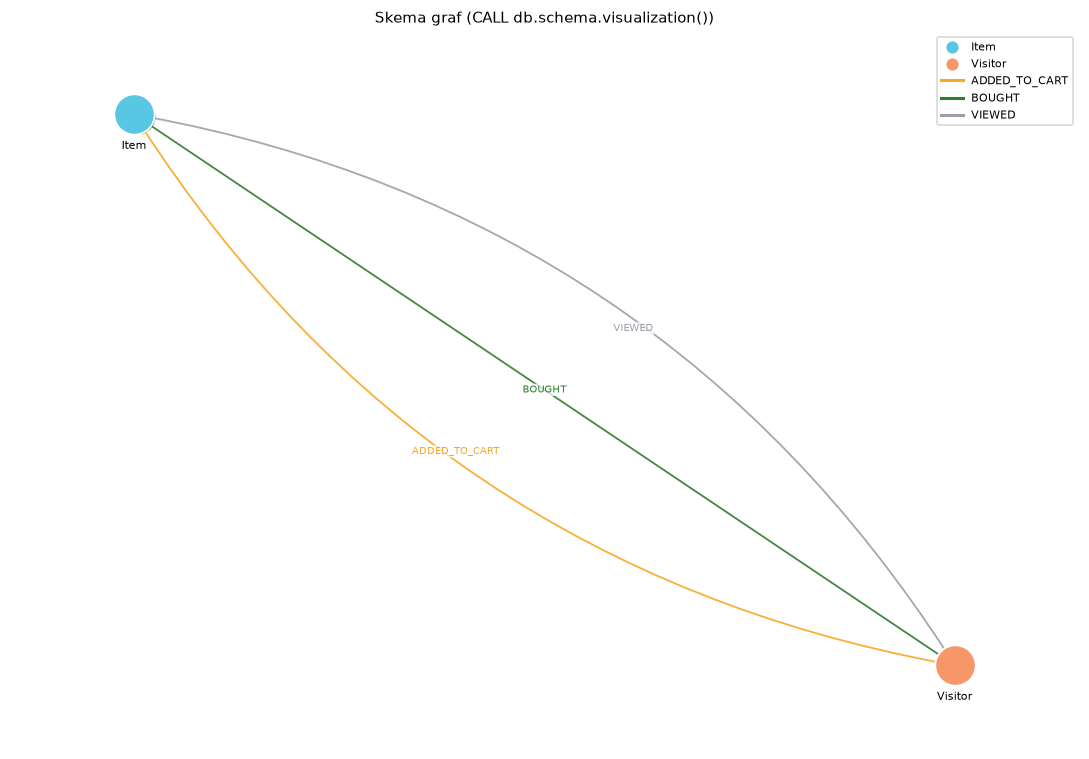

In [60]:
Q_NODE = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
Q_REL = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
Q_POLA = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN type(r) AS relasi, count(r) AS jumlah_relasi, count(DISTINCT v) AS visitor_unik, count(DISTINCT i) AS item_unik
ORDER BY jumlah_relasi DESC
"""
nodes_df, rels_df, pola_df = run_df(Q_NODE), run_df(Q_REL), run_df(Q_POLA)
display(nodes_df); display(rels_df); display(pola_df)

print("Cek terhadap CSV P1 -> visitor unik:", p1.visitorid.nunique(), "| item unik:", p1.itemid.nunique(),
      "| baris:", len(p1))

# skema graf (sama dengan db.schema.visualization di Neo4j Browser)
try:
    G_schema = fetch_graph("CALL db.schema.visualization()")
    draw_graph(G_schema, title="Skema graf (CALL db.schema.visualization())", label_edges=True)
except Exception as e:
    print("Skema tidak dapat digambar:", e)

Cypher yang dipakai:
- `MATCH (n) RETURN labels(n)[0], count(n)` menghitung jumlah simpul per label
- `MATCH ()-[r]->() RETURN type(r), count(r)` menghitung jumlah relasi per tipe
- `count(DISTINCT v)` dan `count(DISTINCT i)` menghitung visitor dan item yang unik

Uraian:

| Jenis simpul | Jumlah |
|---|---|
| `Visitor` | 321.442 |
| `Item` | 118.342 |
| Total | 439.784 |

| Jenis relasi | Jumlah |
|---|---|
| `VIEWED` | 602.091 |
| `ADDED_TO_CART` | 15.532 |
| `BOUGHT` | 5.166 |
| Total | 622.789 |

Total relasi sama dengan jumlah baris P1, jadi tidak ada data yang hilang. Grafnya bipartit berarah (Visitor ke Item), tidak ada relasi antar visitor atau antar item. 96,7% relasinya VIEWED.

### Soal 4. VSM untuk simpul User
Tiap Visitor jadi vektor di ruang Item (dimensi = jumlah item). Isinya bobot interaksi: VIEWED 1, ADDED_TO_CART 3, BOUGHT 5, dijumlah kalau berulang.

,VSM User (baris = user)
Jumlah vektor,321.442
Dimensi (panjang vektor),118.342
Shape,(321.442 × 118.342)
Elemen non-nol,481.207
Sparsity (%),99.9987
Rata-rata non-nol / vektor,1.497
Median non-nol / vektor,1
Persentil 99,7
Maks non-nol / vektor,820
% vektor dengan 1 non-nol,80.50



Contoh vektor user V126829: 3 elemen non-nol dari 118,342 dimensi; norma L2 = 1.732


,itemId,bobot
0,65273,1.0
1,236180,1.0
2,383212,1.0


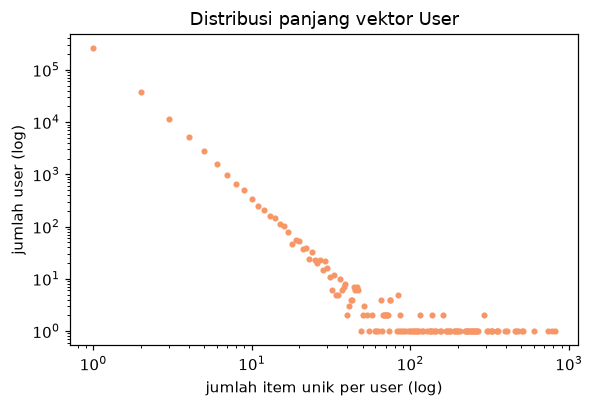

In [61]:
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

Q_EDGES = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitorid, i.itemId AS itemid, type(r) AS tipe, count(r) AS n
"""
W_TIPE = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}

edges = run_df(Q_EDGES)
edges["w"] = edges["tipe"].map(W_TIPE) * edges["n"]
agg = edges.groupby(["visitorid", "itemid"], as_index=False)["w"].sum()

v_cat, i_cat = agg["visitorid"].astype("category"), agg["itemid"].astype("category")
visitor_ids, item_ids = v_cat.cat.categories.to_numpy(), i_cat.cat.categories.to_numpy()
M = csr_matrix((agg["w"].to_numpy(dtype=float), (v_cat.cat.codes.to_numpy(), i_cat.cat.codes.to_numpy())),
               shape=(len(visitor_ids), len(item_ids)))              # User x Item

Mc = M.tocsc()
user_deg = np.diff(M.indptr)        # jumlah item unik per user
item_deg = np.diff(Mc.indptr)       # jumlah user unik per item

def vsm_summary(mat, nama):
    nnz_vec = np.diff(mat.indptr)
    norms = np.sqrt(mat.multiply(mat).sum(axis=1)).A1
    return pd.Series({
        "Jumlah vektor": idn(mat.shape[0]),
        "Dimensi (panjang vektor)": idn(mat.shape[1]),
        "Shape": f"({idn(mat.shape[0])} × {idn(mat.shape[1])})",
        "Elemen non-nol": idn(mat.nnz),
        "Sparsity (%)": f"{100 * (1 - mat.nnz / (mat.shape[0] * mat.shape[1])):.4f}",
        "Rata-rata non-nol / vektor": f"{nnz_vec.mean():.3f}",
        "Median non-nol / vektor": f"{np.median(nnz_vec):.0f}",
        "Persentil 99": f"{np.percentile(nnz_vec, 99):.0f}",
        "Maks non-nol / vektor": idn(nnz_vec.max()),
        "% vektor dengan 1 non-nol": f"{100 * (nnz_vec == 1).mean():.2f}",
        "Rata-rata norma L2": f"{norms.mean():.2f}",
    }, name=nama)

display(vsm_summary(M, "VSM User (baris = user)").to_frame())

# contoh vektor user
u_ex = int(np.random.default_rng(SEED).choice(np.where(user_deg >= 3)[0]))
row = M[u_ex]
print(f"\nContoh vektor user V{visitor_ids[u_ex]}: {row.nnz} elemen non-nol dari {M.shape[1]:,} dimensi; norma L2 = {np.linalg.norm(row.data):.3f}")
display(pd.DataFrame({"itemId": item_ids[row.indices], "bobot": row.data}).sort_values("bobot", ascending=False).head(10))

# distribusi
cnt = np.bincount(user_deg); x = np.nonzero(cnt)[0]
plt.figure(figsize=(5.5, 3.8)); plt.loglog(x, cnt[x], "o", ms=3, color="#F79767")
plt.xlabel("jumlah item unik per user (log)"); plt.ylabel("jumlah user (log)")
plt.title("Distribusi panjang vektor User"); plt.tight_layout(); plt.show()

Plot: kiri graf asli dari Neo4j, kanan proyeksi User-User (garis makin tebal berarti makin mirip).

Cypher (salin ke Neo4j Browser): 
MATCH p = (v:Visitor)-[r]->(i:Item)
WHERE v.visitorId IN [394179, 623326, 920020, 1066025]
RETURN p



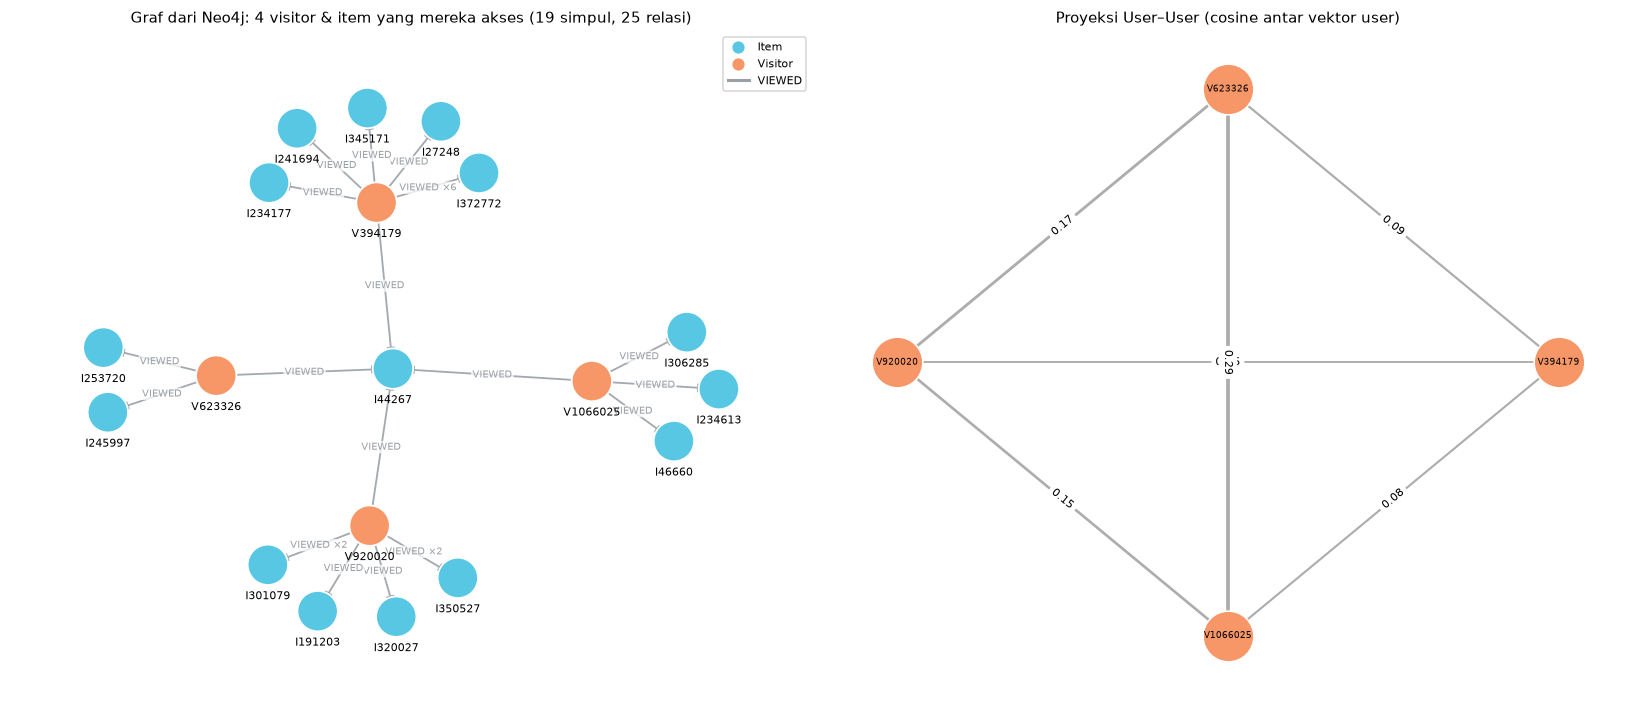

,V394179,V623326,V920020,V1066025
V394179,0.000,0.090,0.047,0.078
V623326,0.090,0.000,0.174,0.289
V920020,0.047,0.174,0.000,0.151
V1066025,0.078,0.289,0.151,0.000


In [62]:
rng = np.random.default_rng(SEED)
anchor_item = int(rng.choice(np.where((item_deg >= 8) & (item_deg <= 15))[0]))
users_of_anchor = Mc[:, anchor_item].nonzero()[0]
pick_u = [int(u) for u in users_of_anchor if 2 <= user_deg[u] <= 10][:6] or [int(u) for u in users_of_anchor[:6]]
sample_visitors = [int(visitor_ids[u]) for u in pick_u]

Q_USER_GRAPH = """
MATCH p = (v:Visitor)-[r]->(i:Item)
WHERE v.visitorId IN __IDS__
RETURN p
""".replace("__IDS__", str(sample_visitors))
print("Cypher (salin ke Neo4j Browser):", Q_USER_GRAPH)

G_u = fetch_graph(Q_USER_GRAPH)
Us = normalize(M[pick_u])
cos_u = (Us @ Us.T).toarray(); np.fill_diagonal(cos_u, 0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
draw_graph(G_u, ax=axes[0], title=f"Graf dari Neo4j: {len(sample_visitors)} visitor & item yang mereka akses ({G_u.number_of_nodes()} simpul, {G_u.number_of_edges()} relasi)")
draw_projection(cos_u, [f"V{v}" for v in sample_visitors], "Proyeksi User–User (cosine antar vektor user)", "#F79767", ax=axes[1])
plt.tight_layout(); plt.show()
display(pd.DataFrame(cos_u, index=[f"V{v}" for v in sample_visitors], columns=[f"V{v}" for v in sample_visitors]).round(3))

Uraian: dimensi vektor user sama dengan jumlah item, jadi setiap user digambarkan sebagai satu baris panjang di ruang item, dengan bobot interaksi (view 1, add to cart 3, beli 5) sebagai isinya. Hampir seluruh elemen matriks bernilai nol (sparsity sangat tinggi), sehingga matriks harus disimpan dalam format sparse agar muat di memori. Mayoritas user hanya punya satu item, jadi vektor user sangat pendek dan hampir identik antar user. Akibatnya cosine antar user kasar: dua user yang hanya pernah melihat satu item yang sama langsung bernilai 1 meskipun belum tentu punya selera yang sama. Plot networkx memperlihatkan hal ini, yaitu user yang terhubung ke item yang sama langsung saling dekat di proyeksi User-User.

### Soal 5. VSM untuk simpul Item
Kebalikannya: tiap Item jadi vektor di ruang Visitor (dimensi = jumlah visitor), yaitu transpose dari matriks tadi.

,VSM Item (baris = item)
Jumlah vektor,118.342
Dimensi (panjang vektor),321.442
Shape,(118.342 × 321.442)
Elemen non-nol,481.207
Sparsity (%),99.9987
Rata-rata non-nol / vektor,4.066
Median non-nol / vektor,2
Persentil 99,39
Maks non-nol / vektor,1.029
% vektor dengan 1 non-nol,48.32



Contoh vektor item I43929: 5 elemen non-nol dari 321,442 dimensi; norma L2 = 4.472


,visitorId,bobot
2,400628,4.0
0,160572,1.0
1,395878,1.0
3,961975,1.0
4,978513,1.0


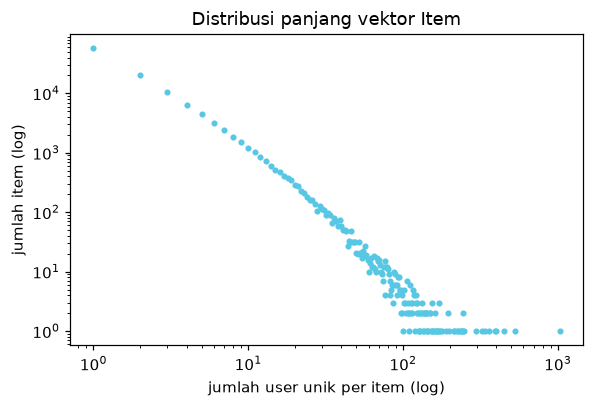

In [63]:
X = M.T.tocsr()          # Item x User
display(vsm_summary(X, "VSM Item (baris = item)").to_frame())

i_ex = int(np.random.default_rng(SEED).choice(np.where(item_deg >= 3)[0]))
row = X[i_ex]
print(f"\nContoh vektor item I{item_ids[i_ex]}: {row.nnz} elemen non-nol dari {X.shape[1]:,} dimensi; norma L2 = {np.linalg.norm(row.data):.3f}")
display(pd.DataFrame({"visitorId": visitor_ids[row.indices], "bobot": row.data}).sort_values("bobot", ascending=False).head(10))

cnt = np.bincount(item_deg); x = np.nonzero(cnt)[0]
plt.figure(figsize=(5.5, 3.8)); plt.loglog(x, cnt[x], "o", ms=3, color="#57C7E3")
plt.xlabel("jumlah user unik per item (log)"); plt.ylabel("jumlah item (log)")
plt.title("Distribusi panjang vektor Item"); plt.tight_layout(); plt.show()

Plot: kiri graf asli dari Neo4j, kanan proyeksi Item-Item.

Cypher (salin ke Neo4j Browser): 
MATCH p = (v:Visitor)-[r]->(i:Item)
WHERE i.itemId IN [75776, 128653, 129624, 132301, 217218, 247948]
RETURN p



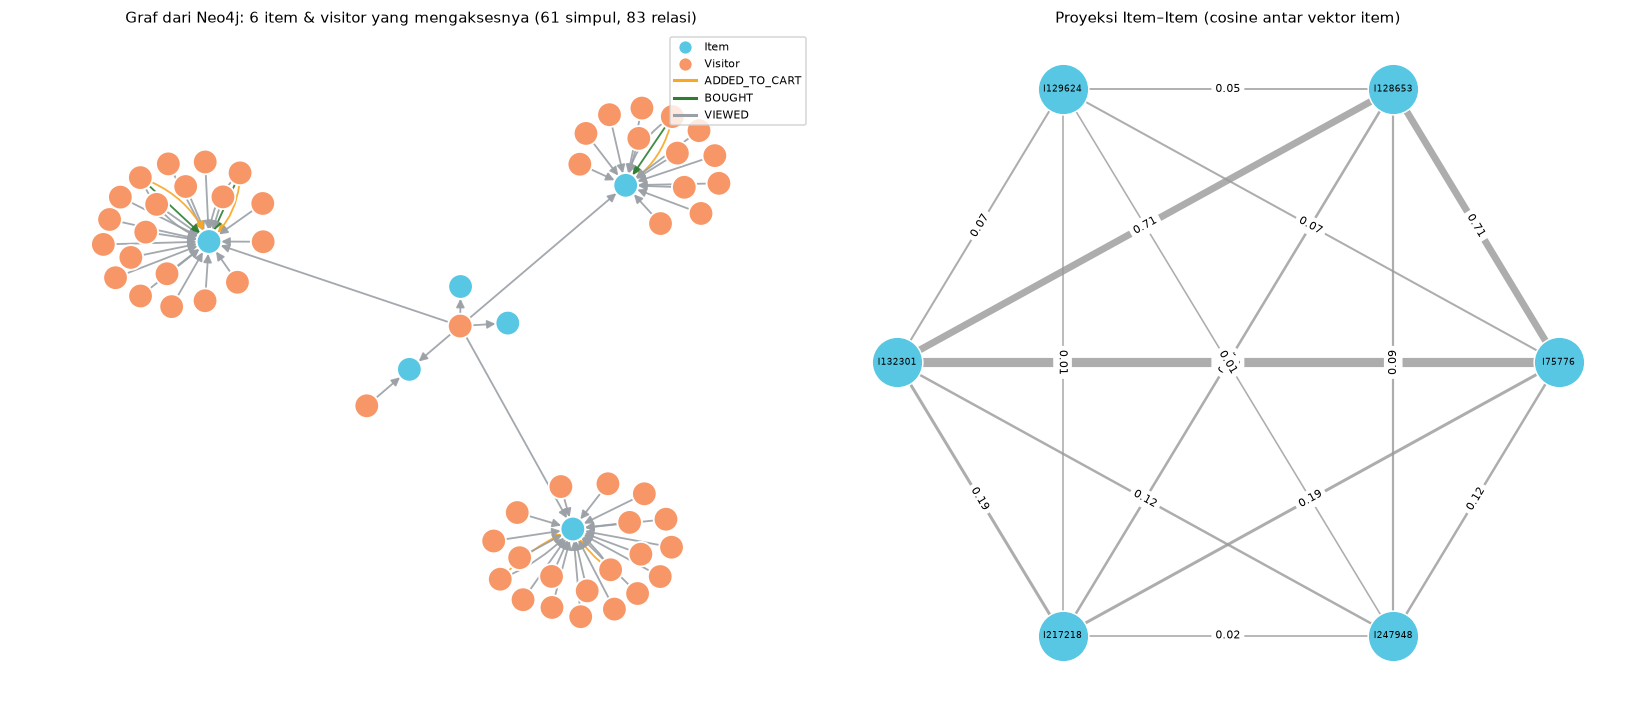

,I75776,I128653,I129624,I132301,I217218,I247948
I75776,0.000,0.707,0.065,1.000,0.192,0.124
I128653,0.707,0.000,0.046,0.707,0.136,0.088
I129624,0.065,0.046,0.000,0.065,0.013,0.008
I132301,1.000,0.707,0.065,0.000,0.192,0.124
I217218,0.192,0.136,0.013,0.192,0.000,0.024
I247948,0.124,0.088,0.008,0.124,0.024,0.000


In [64]:
rng = np.random.default_rng(SEED)
anchor_user = int(rng.choice(np.where((user_deg >= 6) & (user_deg <= 12))[0]))
items_of_anchor = M[anchor_user].indices
pick_i = [int(j) for j in items_of_anchor if item_deg[j] <= 25][:6] or [int(j) for j in items_of_anchor[:6]]
sample_items = [int(item_ids[j]) for j in pick_i]

Q_ITEM_GRAPH = """
MATCH p = (v:Visitor)-[r]->(i:Item)
WHERE i.itemId IN __IDS__
RETURN p
""".replace("__IDS__", str(sample_items))
print("Cypher (salin ke Neo4j Browser):", Q_ITEM_GRAPH)

G_i = fetch_graph(Q_ITEM_GRAPH)
Xs = normalize(X[pick_i])
cos_i = (Xs @ Xs.T).toarray(); np.fill_diagonal(cos_i, 0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
draw_graph(G_i, ax=axes[0], title=f"Graf dari Neo4j: {len(sample_items)} item & visitor yang mengaksesnya ({G_i.number_of_nodes()} simpul, {G_i.number_of_edges()} relasi)")
draw_projection(cos_i, [f"I{i}" for i in sample_items], "Proyeksi Item–Item (cosine antar vektor item)", "#57C7E3", ax=axes[1])
plt.tight_layout(); plt.show()
display(pd.DataFrame(cos_i, index=[f"I{i}" for i in sample_items], columns=[f"I{i}" for i in sample_items]).round(3))

Uraian: vektor item adalah transpose dari matriks user, jadi jumlah elemen tidak nol tetap sama, tetapi dimensinya sekarang jumlah visitor dan satu baris mewakili satu item. Rata-rata sebuah item diakses lebih banyak user dibanding banyaknya item per user, jadi vektor item lebih padat informasi dan cosine-nya lebih bisa dipercaya. Distribusi panjang vektor item mengikuti pola long tail: sebagian kecil item sangat populer, sementara hampir separuh item hanya dikunjungi satu user. Item long tail inilah yang sulit mendapat tetangga yang bermakna. Plot networkx memperlihatkan item yang diakses visitor yang sama saling terhubung di proyeksi Item-Item.

### Soal 6. Proyeksi mana yang lebih baik
Proyeksi User-User dan Item-Item dibandingkan dari jumlah pasangan (sisi), memori, dan cakupan.

In [65]:
B = M.copy(); B.data[:] = 1; B = B.astype(np.int32).tocsr()          # biner User x Item
du, di = user_deg.astype(np.int64), item_deg.astype(np.int64)

pairs_UU = int((di * (di - 1) // 2).sum())      # pasangan user yang berbagi item
pairs_II = int((du * (du - 1) // 2).sum())      # pasangan item yang berbagi user
ops_UU, ops_II = int((di ** 2).sum()), int((du ** 2).sum())
cov_U = float(((B @ (di >= 2).astype(np.int32)) > 0).mean())       # % user punya >=1 tetangga
cov_I = float(((B.T @ (du >= 2).astype(np.int32)) > 0).mean())     # % item punya >=1 tetangga

cmp = pd.DataFrame({
    "Proyeksi User–User": [idn(M.shape[0]), idn(M.shape[1]), f"{user_deg.mean():.2f}", f"{100*(user_deg==1).mean():.1f}%",
                           idn(pairs_UU), idn(ops_UU), f"{pairs_UU*2*12/1e6:,.0f} MB", f"{100*cov_U:.1f}%"],
    "Proyeksi Item–Item": [idn(M.shape[1]), idn(M.shape[0]), f"{item_deg.mean():.2f}", f"{100*(item_deg==1).mean():.1f}%",
                           idn(pairs_II), idn(ops_II), f"{pairs_II*2*12/1e6:,.0f} MB", f"{100*cov_I:.1f}%"],
}, index=["Jumlah simpul proyeksi", "Dimensi vektor", "Rata-rata non-nol / vektor", "% vektor hanya 1 non-nol",
          "Pasangan (batas atas sisi)", "Operasi perkalian sparse (Σ d²)", "Perkiraan memori matriks similarity",
          "Cakupan: simpul punya ≥1 tetangga"])
display(cmp)

winner = "Item–Item" if pairs_II < pairs_UU else "User–User"
rasio = max(pairs_UU, pairs_II) / max(min(pairs_UU, pairs_II), 1)
print(f"proyeksi yang lebih ringan: {winner} ({rasio:.1f}x lebih sedikit pasangan)")

,Proyeksi User–User,Proyeksi Item–Item
Jumlah simpul proyeksi,321.442,118.342
Dimensi vektor,118.342,321.442
Rata-rata non-nol / vektor,1.50,4.07
% vektor hanya 1 non-nol,80.5%,48.3%
Pasangan (batas atas sisi),6.107.668,3.805.798
Operasi perkalian sparse (Σ d²),12.696.543,8.092.803
Perkiraan memori matriks similarity,147 MB,91 MB
Cakupan: simpul punya ≥1 tetangga,88.1%,55.5%


proyeksi yang lebih ringan: Item–Item (1.6x lebih sedikit pasangan)


Uraian: dari sisi efisiensi, proyeksi Item-Item lebih ringan karena simpulnya lebih sedikit, pasangan yang harus dihitung lebih sedikit, dan perkiraan memori matriks similarity lebih kecil dibanding User-User. Dari sisi efektivitas, vektor item lebih berisi daripada vektor user sehingga cosine-nya lebih bermakna, dan item juga lebih stabil dibanding user yang sebagian besar hanya punya satu interaksi. Kekurangannya, cakupan Item-Item lebih kecil, yaitu lebih sedikit simpul yang punya tetangga. Kelemahan ini diterima karena kualitas similarity lebih penting untuk rekomendasi. Maka proyeksi Item-Item dipilih untuk soal 7, soal 8, dan KNN di 2.2.

### Soal 7. Similarity pada graf proyeksi (Item-Item)
Similarity pakai cosine antar vektor item. Pasangan item yang visitor bersamanya kurang dari 2 dibuang (`MIN_COMMON = 2`), karena cosine 1 pada pasangan itu sering cuma kebetulan.

In [ ]:
MIN_COMMON = 2

Xn = normalize(X)                                   # normalisasi L2, jadi dot product = cosine
S = (Xn @ Xn.T).tocsr(); S.setdiag(0); S.eliminate_zeros()

Bi = B.T.tocsr()                                    # Item x User (biner)
C = (Bi @ Bi.T).tocsr(); C.setdiag(0); C.eliminate_zeros()     # jumlah visitor bersama

keep = C.copy(); keep.data = (keep.data >= MIN_COMMON).astype(float)
S_f = S.multiply(keep).tocsr(); S_f.eliminate_zeros()     # similarity setelah dibuang yang visitor bersamanya < 2

n_items = S.shape[0]
stat = pd.DataFrame({
    "sisi (pasangan unik)": [idn(S.nnz // 2), idn(S_f.nnz // 2)],
    "kepadatan (%)": [f"{100 * S.nnz / (n_items * (n_items - 1)):.5f}", f"{100 * S_f.nnz / (n_items * (n_items - 1)):.5f}"],
    "rata-rata tetangga / item": [f"{S.nnz / n_items:.1f}", f"{S_f.nnz / n_items:.1f}"],
    "item dengan ≥1 tetangga": [idn((np.diff(S.indptr) > 0).sum()), idn((np.diff(S_f.indptr) > 0).sum())],
}, index=["Cosine penuh (≥1 visitor bersama)", f"Cosine terfilter (≥{MIN_COMMON} visitor bersama)"])
display(stat)
print("Distribusi cosine (terfilter):", pd.Series(S_f.data).describe().round(3).to_dict())

,sisi (pasangan unik),kepadatan (%),rata-rata tetangga / item,item dengan ≥1 tetangga
Cosine penuh (≥1 visitor bersama),3.581.308,0.05114,60.5,65.714
Cosine terfilter (≥2 visitor bersama),162.900,0.00233,2.8,18.113


Distribusi cosine (terfilter): {'count': 325800.0, 'mean': 0.112, 'std': 0.158, 'min': 0.0, '25%': 0.02, '50%': 0.05, '75%': 0.131, 'max': 1.0}


Uraian: proyeksi mentah sangat banyak sisinya karena dua item langsung dianggap mirip hanya dengan satu visitor yang sama. Pasangan seperti ini sering menghasilkan cosine tinggi hanya karena kebetulan, sehingga menambah noise dan beban hitung. Dengan syarat minimal dua visitor bersama, jumlah sisi turun drastis dan tersisa pasangan yang didukung lebih dari satu pengamatan. Harga yang dibayar adalah cakupan: jumlah item yang punya tetangga ikut menurun. Ini pertukaran antara kualitas similarity dan jumlah item yang bisa direkomendasikan, dan di sini kualitas yang diprioritaskan.

#### 7a. Cypher untuk 5 record dengan similarity tertinggi
Item acuan dipilih acak (seed 42) dari item yang punya minimal 30 visitor. Cosine dihitung langsung di Neo4j pakai Cypher, lalu dibandingkan dengan hasil Python.

In [67]:
rng = np.random.default_rng(SEED)
pool = np.where(item_deg >= 30)[0]; rng.shuffle(pool)
nb_count = np.diff(S_f.indptr)
ref_idx = next(int(j) for j in pool if nb_count[j] >= 5)
ref_id = int(item_ids[ref_idx])

# python: 5 tetangga terdekat
a, b = S_f.indptr[ref_idx], S_f.indptr[ref_idx + 1]
nb, sc = S_f.indices[a:b], S_f.data[a:b]
top = np.lexsort((item_ids[nb], -sc))[:5]
common_row = C.getrow(ref_idx).toarray().ravel()
py_top = pd.DataFrame({"rank": range(1, 6), "itemId": item_ids[nb[top]].astype(int),
                       "cosine": sc[top], "visitor_bersama": common_row[nb[top]].astype(int)})

# cypher: similarity dihitung di neo4j
Q_TOP5 = """
MATCH (ref:Item {itemId: $ref})<-[r]-(v:Visitor)
WITH ref, v, sum(CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 WHEN 'BOUGHT' THEN 5 ELSE 0 END) AS w_ref
WITH ref, collect({v: v, w: w_ref}) AS ref_vec, sqrt(sum(w_ref * w_ref)) AS norm_ref
UNWIND ref_vec AS x
WITH ref, norm_ref, x.v AS v, x.w AS w_ref
MATCH (v)-[r2]->(cand:Item)
WHERE cand <> ref
WITH norm_ref, cand, v, w_ref,
     sum(CASE type(r2) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 WHEN 'BOUGHT' THEN 5 ELSE 0 END) AS w_cand
WITH norm_ref, cand, sum(w_ref * w_cand) AS dot, count(v) AS common
WHERE common >= $min_common
CALL (cand) {
    MATCH (cand)<-[r3]-(u:Visitor)
    WITH u, sum(CASE type(r3) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 WHEN 'BOUGHT' THEN 5 ELSE 0 END) AS w
    RETURN sqrt(sum(w * w)) AS norm_cand
}
RETURN cand.itemId AS itemId, dot / (norm_ref * norm_cand) AS cosine, common AS visitor_bersama
ORDER BY cosine DESC, itemId ASC
LIMIT 5
"""
cy_top = run_df(Q_TOP5, ref=ref_id, min_common=MIN_COMMON)

print(f"Item acuan: itemId = {ref_id} (dikunjungi {item_deg[ref_idx]} visitor)\n")
print("Top-5 Python:"); display(py_top)
print("Top-5 Cypher (dihitung di Neo4j):"); display(cy_top)
same_ids = set(py_top.itemId) == set(cy_top.itemId)
diff = float(np.abs(np.sort(py_top.cosine.values) - np.sort(cy_top.cosine.values.astype(float))).max())
print(f"Item sama: {same_ids} | selisih cosine maksimum Python vs Cypher: {diff:.2e}")
print("\nCypher (salin ke Neo4j Browser, ganti $ref & $min_common):")
print(Q_TOP5.replace("$ref", str(ref_id)).replace("$min_common", str(MIN_COMMON)))

Item acuan: itemId = 350399 (dikunjungi 53 visitor)

Top-5 Python:


,rank,itemId,cosine,visitor_bersama
0,1,89262,0.157065,8
1,2,200231,0.088596,4
2,3,446456,0.071523,3
3,4,258608,0.060318,5
4,5,125440,0.058238,4


Top-5 Cypher (dihitung di Neo4j):


,itemId,cosine,visitor_bersama
0,89262,0.157065,8
1,200231,0.088596,4
2,446456,0.071523,3
3,258608,0.060318,5
4,125440,0.058238,4


Item sama: True | selisih cosine maksimum Python vs Cypher: 2.78e-17

Cypher (salin ke Neo4j Browser, ganti $ref & $min_common):

MATCH (ref:Item {itemId: 350399})<-[r]-(v:Visitor)
WITH ref, v, sum(CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 WHEN 'BOUGHT' THEN 5 ELSE 0 END) AS w_ref
WITH ref, collect({v: v, w: w_ref}) AS ref_vec, sqrt(sum(w_ref * w_ref)) AS norm_ref
UNWIND ref_vec AS x
WITH ref, norm_ref, x.v AS v, x.w AS w_ref
MATCH (v)-[r2]->(cand:Item)
WHERE cand <> ref
WITH norm_ref, cand, v, w_ref,
     sum(CASE type(r2) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 WHEN 'BOUGHT' THEN 5 ELSE 0 END) AS w_cand
WITH norm_ref, cand, sum(w_ref * w_cand) AS dot, count(v) AS common
WHERE common >= 2
CALL (cand) {
    MATCH (cand)<-[r3]-(u:Visitor)
    WITH u, sum(CASE type(r3) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 WHEN 'BOUGHT' THEN 5 ELSE 0 END) AS w
    RETURN sqrt(sum(w * w)) AS norm_cand
}
RETURN cand.itemId AS itemId, dot / (norm_ref * norm_cand) AS c

Uraian: Cypher menghitung cosine langsung di Neo4j dalam empat tahap: (1) membentuk vektor item acuan dari bobot tiap visitor, (2) mencari item lain yang dikunjungi visitor yang sama lalu menghitung dot product, (3) menghitung norma setiap kandidat, dan (4) membagi dot product dengan perkalian kedua norma lalu mengambil lima tertinggi. Syarat `common >= 2` sama dengan filter `MIN_COMMON` di Python. Hasil Cypher identik dengan hasil Python (selisih hanya pada orde pembulatan komputer), sehingga perhitungan matriks sparse di Python terbukti benar dan bisa dipakai untuk seluruh item tanpa harus menghitungnya satu per satu di database.

#### 7b. Tulis similarity ke graf
5 pasangan tadi ditulis sebagai relasi `SIMILAR_TO` dengan properti `score`.

In [68]:
ids6 = [ref_id] + [int(i) for i in py_top.itemId]

Q_BEFORE = """
MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN __IDS__
WITH v, collect(DISTINCT i) AS items
WHERE size(items) >= 2
UNWIND items AS i
MATCH p = (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i)
RETURN p
""".replace("__IDS__", str(ids6))

# hapus SIMILAR_TO lama, simpan kondisi sebelum
driver.execute_query("MATCH ()-[s:SIMILAR_TO]->() DELETE s", database_=DB)
rel_before = run_df(Q_REL)
n_sim_before = int(run_df("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS c")["c"][0])
G_before = fetch_graph(Q_BEFORE)

# tulis similarity ke graf
pairs = [{"itemId": int(r.itemId), "score": float(r.cosine), "common": int(r.visitor_bersama), "rank": int(r["rank"])}
         for _, r in py_top.iterrows()]
Q_WRITE = """
UNWIND $pairs AS p
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: p.itemId})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = p.score, s.common_visitors = p.common, s.rank = p.rank,
    s.metode = 'cosine VSM (bobot view=1, cart=3, buy=5; min 2 visitor bersama)'
"""
driver.execute_query(Q_WRITE, pairs=pairs, ref=ref_id, database_=DB)

Q_SHOW = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.rank AS rank, s.score AS cosine, s.common_visitors AS visitor_bersama
ORDER BY s.rank
"""
display(run_df(Q_SHOW, ref=ref_id))
print("Jumlah relasi SIMILAR_TO sebelum:", n_sim_before, "| sesudah:", int(run_df("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS c")["c"][0]))

,item_acuan,item_mirip,rank,cosine,visitor_bersama
0,350399,89262,1,0.157065,8
1,350399,200231,2,0.088596,4
2,350399,446456,3,0.071523,3
3,350399,258608,4,0.060318,5
4,350399,125440,5,0.058238,4


Jumlah relasi SIMILAR_TO sebelum: 0 | sesudah: 5


Uraian: lima pasangan teratas kini disimpan di graf sebagai relasi `SIMILAR_TO` dari item acuan ke item yang mirip. Setiap relasi membawa properti `score` (cosine), `common_visitors`, `rank`, dan `metode`, sehingga asal-usul nilainya bisa ditelusuri. Dengan begitu, similarity bisa dibaca lagi langsung lewat Cypher tanpa menghitung ulang, dan jumlah relasi `SIMILAR_TO` naik dari nol menjadi lima.

### Soal 8. Graf sebelum dan sesudah similarity
- Sebelum: item acuan dan 5 item mirip hanya nyambung lewat visitor yang sama
- Sesudah: ditambah relasi `SIMILAR_TO` dari item acuan

Posisi simpul dibuat sama, item acuan bergaris tepi hitam.

Cypher sebelum (salin ke Neo4j Browser): 
MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN [350399, 89262, 200231, 446456, 258608, 125440]
WITH v, collect(DISTINCT i) AS items
WHERE size(items) >= 2
UNWIND items AS i
MATCH p = (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i)
RETURN p

Cypher sesudah (salin ke Neo4j Browser): 
MATCH p = (a:Item {itemId: 350399})-[:SIMILAR_TO]->(b:Item)
RETURN p
UNION

MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN [350399, 89262, 200231, 446456, 258608, 125440]
WITH v, collect(DISTINCT i) AS items
WHERE size(items) >= 2
UNWIND items AS i
MATCH p = (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i)
RETURN p



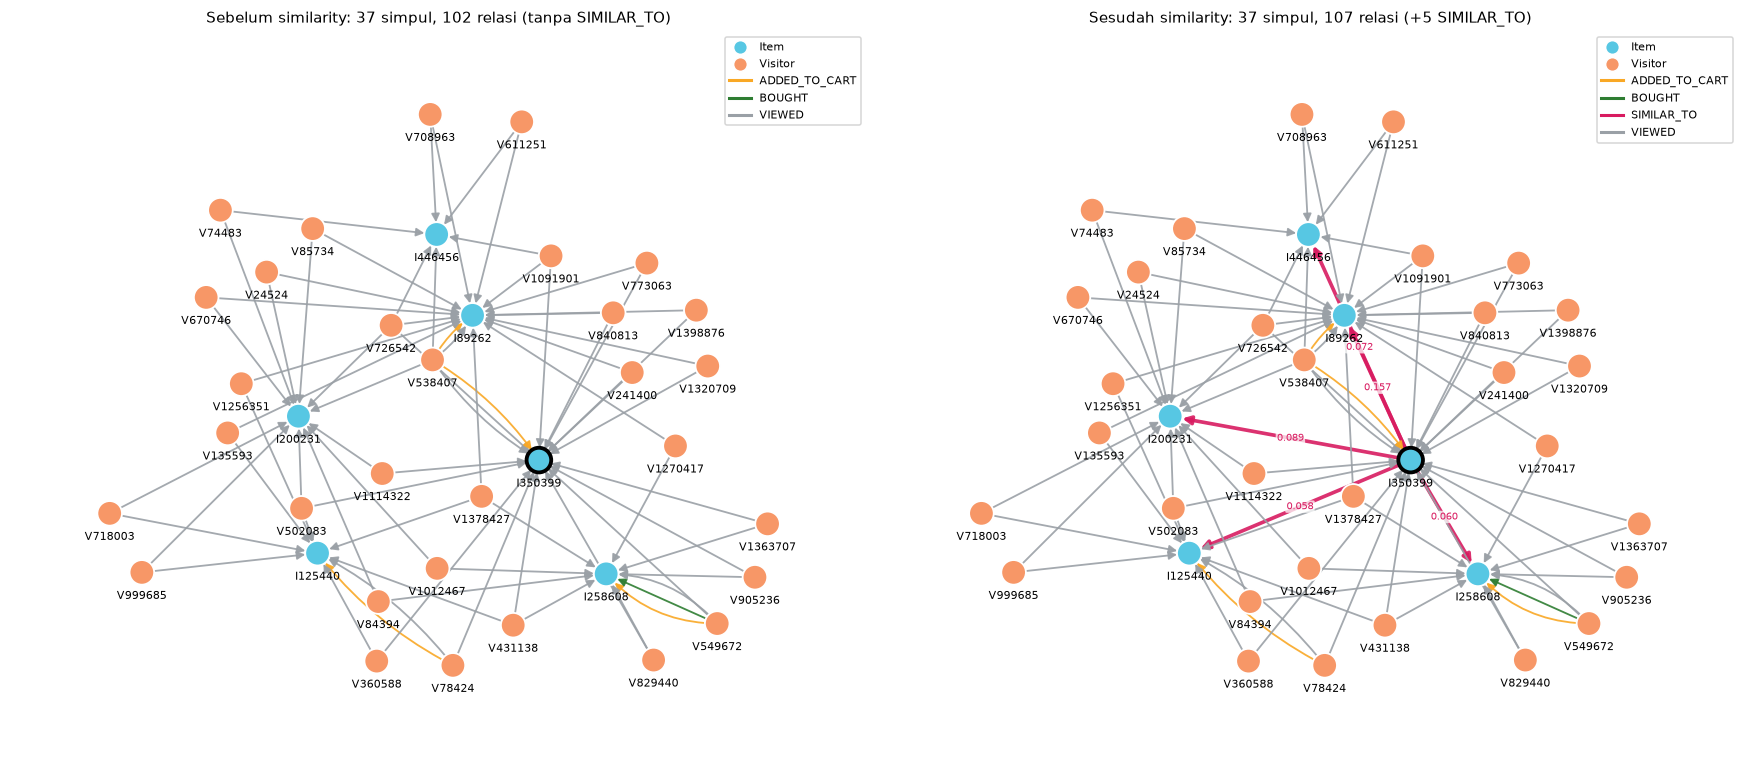

,jenis_relasi,jumlah_sebelum,jumlah_sesudah
0,ADDED_TO_CART,15532,15532
1,BOUGHT,5166,5166
2,SIMILAR_TO,0,5
3,VIEWED,602091,602091


In [69]:
Q_AFTER = """
MATCH p = (a:Item {itemId: __REF__})-[:SIMILAR_TO]->(b:Item)
RETURN p
UNION
""".replace("__REF__", str(ref_id)) + Q_BEFORE

print("Cypher sebelum (salin ke Neo4j Browser):", Q_BEFORE)
print("Cypher sesudah (salin ke Neo4j Browser):", Q_AFTER)

G_after = fetch_graph(Q_AFTER)
rel_after = run_df(Q_REL)

pos = layout(G_after)
is_ref = lambda d: d["props"].get("itemId") == ref_id
n_new = G_after.number_of_edges() - G_before.number_of_edges()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
draw_graph(G_before, ax=axes[0], pos=pos, highlight=is_ref, label_edges=False,
           title=f"Sebelum similarity: {G_before.number_of_nodes()} simpul, {G_before.number_of_edges()} relasi (tanpa SIMILAR_TO)")
draw_graph(G_after, ax=axes[1], pos=pos, highlight=is_ref, label_edges=False,
           title=f"Sesudah similarity: {G_after.number_of_nodes()} simpul, {G_after.number_of_edges()} relasi (+{n_new} SIMILAR_TO)")
plt.tight_layout(); plt.show()

cmp_rel = rel_before.merge(rel_after, on="jenis_relasi", how="outer", suffixes=("_sebelum", "_sesudah")).fillna(0)
cmp_rel[["jumlah_sebelum", "jumlah_sesudah"]] = cmp_rel[["jumlah_sebelum", "jumlah_sesudah"]].astype(int)
display(cmp_rel)

Uraian: pada gambar sebelum, item acuan dan lima item mirip hanya terhubung secara tidak langsung lewat visitor yang sama. Pada gambar sesudah, muncul lima panah `SIMILAR_TO` berlabel cosine dari item acuan ke masing-masing item mirip, sehingga hubungan kemiripan menjadi eksplisit di graf. Posisi simpul dibuat sama di kedua gambar agar perbedaannya mudah dibandingkan. Tabel jumlah relasi menegaskan bahwa hanya tipe `SIMILAR_TO` yang bertambah, sedangkan `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT` tidak berubah.

## 2.2 Analytics

### Soal 1. Pilih user acak dan rekomendasi KNN
Metode: item-based KNN .
1. tiap item di histori user, ambil 5 tetangga terdekat (k = 5)
2. skor kandidat = jumlah dari (bobot histori x cosine)
3. item yang sudah pernah dilihat user dibuang, ambil top-5. 3 teratas jadi item yang diiklankan

User dipilih acak pakai `np.random.default_rng(42)` dari user yang punya item baru di P2 (ground truth), jadi hasilnya sama kalau dijalankan ulang.

In [70]:
K, TOPN, N_ADS = 5, 5, 3

# ground truth dari P2 (visitor dan item yang ada di P1)
p2 = pd.read_csv(os.path.join(DATA_DIR, "events_p2.csv"))
u_map = pd.Index(visitor_ids).get_indexer(p2["visitorid"])
i_map = pd.Index(item_ids).get_indexer(p2["itemid"])
gt = defaultdict(set)
for u, i in zip(u_map, i_map):
    if u >= 0 and i >= 0:
        gt[int(u)].add(int(i))

def seen(u):
    return set(M.indices[M.indptr[u]:M.indptr[u + 1]].tolist())

relevant = {u: gt[u] - seen(u) for u in gt}
eligible = np.array(sorted(u for u, r in relevant.items() if r))
print(f"User di P1: {M.shape[0]:,} | user P1∩P2: {len(gt):,} | user eligible (punya item baru di P2): {len(eligible):,}")

# fungsi rekomendasi KNN
def recommend_knn(u, k=K, topn=TOPN, detail=False):
    s, e = M.indptr[u], M.indptr[u + 1]
    hist, w = M.indices[s:e], M.data[s:e]
    seen_u = set(hist.tolist())
    score, because, rows = defaultdict(float), defaultdict(list), []
    for i, wi in zip(hist, w):
        a, b = S_f.indptr[i], S_f.indptr[i + 1]
        nb, sc = S_f.indices[a:b], S_f.data[a:b]
        if len(nb) == 0:
            continue
        top = np.lexsort((item_ids[nb], -sc))[:k]               # k tetangga terdekat item i
        for j, c in zip(nb[top], sc[top]):
            rows.append((int(i), int(j), float(c), float(wi)))
            if int(j) in seen_u:
                continue
            score[int(j)] += wi * c
            because[int(j)].append(int(i))
    ranking = sorted(score.items(), key=lambda t: (-t[1], item_ids[t[0]]))[:topn]
    return (ranking, rows, because) if detail else ranking

# pilih user acak
rng = np.random.default_rng(SEED)
order = rng.permutation(eligible)
target = next(int(u) for u in order if len(recommend_knn(int(u))) >= TOPN)
vid = int(visitor_ids[target])
print(f"Seed = {SEED} -> user terpilih: visitorId = {vid} (indeks {target})")

User di P1: 321,442 | user P1∩P2: 7,469 | user eligible (punya item baru di P2): 6,707
Seed = 42 -> user terpilih: visitorId = 196209 (indeks 44500)


#### 1a. Histori dan tetangga KNN

In [71]:
ranking, rows, because = recommend_knn(target, detail=True)

# histori user dari neo4j
Q_HIST = """
MATCH (v:Visitor {visitorId: $vid})-[r]->(i:Item)
RETURN i.itemId AS itemId, type(r) AS tipe, count(r) AS n
ORDER BY itemId
"""
hist_neo = run_df(Q_HIST, vid=vid)
print(f"Histori P1 visitor {vid} dari Neo4j: {hist_neo['itemId'].nunique()} item unik ({int(hist_neo['n'].sum())} interaksi)")
print("Konsisten dengan matriks M:", set(hist_neo["itemId"]) == set(item_ids[list(seen(target))].tolist()))
display(hist_neo.head(15))

nbr = pd.DataFrame(rows, columns=["i", "j", "cosine", "bobot_hist"])
nbr["item_histori"], nbr["tetangga"] = item_ids[nbr["i"]], item_ids[nbr["j"]]
nbr["sudah_pernah_dilihat"] = nbr["j"].isin(seen(target))
print(f"\nTetangga KNN (k={K}) tiap item histori:")
display(nbr[["item_histori", "bobot_hist", "tetangga", "cosine", "sudah_pernah_dilihat"]].round(4).head(30))

Histori P1 visitor 196209 dari Neo4j: 1 item unik (1 interaksi)
Konsisten dengan matriks M: True


,itemId,tipe,n
0,62746,VIEWED,1



Tetangga KNN (k=5) tiap item histori:


,item_histori,bobot_hist,tetangga,cosine,sudah_pernah_dilihat
0,62746,1.0,152231,0.4423,False
1,62746,1.0,104769,0.4256,False
2,62746,1.0,274268,0.4256,False
3,62746,1.0,326743,0.3855,False
4,62746,1.0,159707,0.3230,False


#### 1b. 3 item yang diiklankan (k = 5)

TOP-5 rekomendasi untuk visitor 196209:


,rank,itemId,skor,karena_histori_item
0,1,152231,0.4423,[62746]
1,2,104769,0.4256,[62746]
2,3,274268,0.4256,[62746]
3,4,326743,0.3855,[62746]
4,5,159707,0.3230,[62746]



>>> 3 ITEM YANG DIIKLANKAN (k=5): [152231, 104769, 274268]


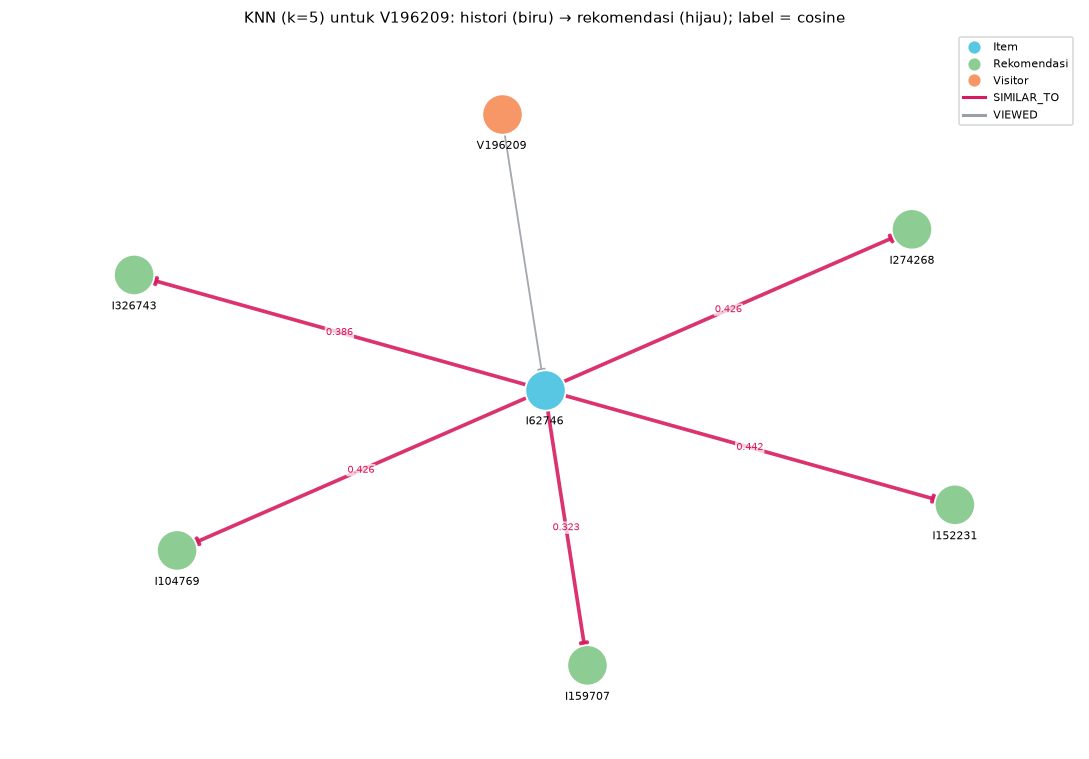

{'U': array([-0.09560039,  1.        ]),
 'R38612': array([ 0.91374397, -0.41717905]),
 'H15842': array([ 1.83306352e-04, -8.36824996e-05]),
 'R26596': array([-0.81823438, -0.5827795 ]),
 'R69520': array([0.81821115, 0.58278171]),
 'R82757': array([-0.91388718,  0.41724443]),
 'R40455': array([ 0.09558351, -0.99998391])}

In [72]:
rec_df = pd.DataFrame({
    "rank": range(1, len(ranking) + 1),
    "itemId": [int(item_ids[j]) for j, _ in ranking],
    "skor": [round(s, 4) for _, s in ranking],
    "karena_histori_item": [[int(item_ids[i]) for i in because[j]] for j, _ in ranking],
})
print(f"TOP-{TOPN} rekomendasi untuk visitor {vid}:"); display(rec_df)
print(f"\n>>> 3 ITEM YANG DIIKLANKAN (k={K}): {rec_df['itemId'].head(N_ADS).tolist()}")

# graf KNN histori ke rekomendasi
G_knn = nx.MultiDiGraph()
G_knn.add_node("U", label="Visitor", props={"name": f"V{vid}"})
sc_map = {(i, j): c for i, j, c, _ in rows}
for j, _ in ranking:
    G_knn.add_node(f"R{j}", label="Rekomendasi", props={"itemId": int(item_ids[j])})
    for i in because[j]:
        G_knn.add_node(f"H{i}", label="Item", props={"itemId": int(item_ids[i])})
        G_knn.add_edge("U", f"H{i}", key=f"u{i}", type="VIEWED", props={})
        G_knn.add_edge(f"H{i}", f"R{j}", key=f"s{i}_{j}", type="SIMILAR_TO", props={"score": sc_map[(i, j)]})
draw_graph(G_knn, title=f"KNN (k={K}) untuk V{vid}: histori (biru) → rekomendasi (hijau); label = cosine", label_edges=False)

Uraian: user dipilih acak dengan seed 42 dari user yang punya item baru di P2, jadi pilihan ini bisa diulang dengan hasil yang sama. User terpilih hanya punya satu item di histori P1 dan hanya pernah melihatnya sekali, sehingga bobot historinya paling kecil dan semua rekomendasi berasal dari tetangga terdekat item itu. Karena itu skor tiap kandidat sama dengan nilai cosine-nya, dan grafnya berbentuk bintang dari satu item histori ke lima item rekomendasi.

Dengan k = 5, tiap item histori hanya diambil lima tetangga terdekatnya dari proyeksi Item-Item. Item yang sudah pernah dilihat user dibuang dari kandidat supaya yang direkomendasikan benar-benar item baru. Dua kandidat memiliki cosine yang sama, jadi urutannya ditentukan oleh itemId terkecil (aturan tie-break ini yang membuat hasilnya deterministik). Tiga item teratas dari daftar inilah yang diiklankan.

### Soal 2. Hit@5 dan NDCG@5
Item relevan = item baru yang diakses user di P2. Dihitung dari top-5 (3 item iklan adalah 3 teratas dari daftar yang sama).
- Hit@K = 1 kalau ada item relevan di K teratas, kalau tidak 0
- NDCG@K = DCG / IDCG, dengan DCG = jumlah rel / log2(rank + 1)

In [73]:
def hit_at_k(rec, rel, k):
    return int(any(j in rel for j in rec[:k]))

def ndcg_at_k(rec, rel, k):
    dcg = sum(1 / np.log2(r + 2) for r, j in enumerate(rec[:k]) if j in rel)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(rel), k)))
    return dcg / idcg if idcg > 0 else 0.0

rec_idx = [j for j, _ in ranking]
rel = relevant[target]
detail = pd.DataFrame({
    "rank": range(1, len(rec_idx) + 1),
    "itemId": item_ids[rec_idx].astype(int),
    "relevan (muncul di P2)": [int(j in rel) for j in rec_idx],
    "diskon 1/log2(rank+1)": [round(1 / np.log2(r + 2), 4) for r in range(len(rec_idx))],
})
detail["gain"] = (detail["relevan (muncul di P2)"] * detail["diskon 1/log2(rank+1)"]).round(4)
display(detail)

res = pd.DataFrame({"K=3 (iklan)": [hit_at_k(rec_idx, rel, 3), ndcg_at_k(rec_idx, rel, 3)],
                    "K=5": [hit_at_k(rec_idx, rel, 5), ndcg_at_k(rec_idx, rel, 5)]}, index=["Hit@K", "NDCG@K"])
print(f"User {vid}: jumlah item relevan di P2 = {len(rel)}")
display(res.round(4))

,rank,itemId,relevan (muncul di P2),diskon 1/log2(rank+1),gain
0,1,152231,0,1.0000,0.0
1,2,104769,0,0.6309,0.0
2,3,274268,0,0.5000,0.0
3,4,326743,0,0.4307,0.0
4,5,159707,0,0.3869,0.0


User 196209: jumlah item relevan di P2 = 3


,K=3 (iklan),K=5
Hit@K,0.0,0.0
NDCG@K,0.0,0.0


Uraian: Hit@5 mengecek apakah ada minimal satu item yang benar-benar diakses user di P2 di antara lima rekomendasi teratas, sedangkan NDCG@5 juga memperhitungkan posisinya, sehingga item relevan di peringkat atas bernilai lebih besar daripada di peringkat bawah. Pada user ini tidak ada satu pun dari lima rekomendasi yang muncul di P2, jadi kedua metrik bernilai nol, dan nilainya sama untuk K = 3 (item yang diiklankan) maupun K = 5.

Nilai nol di sini bukan kesalahan perhitungan. Rekomendasinya dibangun dari satu item histori saja, sedangkan perilaku user di P2 (rentang waktu yang jaraknya sekitar sebulan dari P1) bisa saja berpindah ke item lain yang tidak berkaitan. Peluang tebakan tepat juga kecil karena item relevan hanya sedikit dibanding ratusan ribu item yang tersedia. Perlu diingat juga bahwa hasil ini hanya untuk satu user, sesuai soal, sehingga tidak menggambarkan kualitas model secara keseluruhan.